# DemandIQ - Stage 1: Data audit + chronological baseline

Runs the `diq_model` package over the two audited datasets and renders the
report figures **from the same run that produced the metrics** - no
hand-copied numbers.

| Dataset | Rows | Role |
| --- | --- | --- |
| Recruit Restaurant Visitor Forecasting (Kaggle, academic use) | 252,108 visits / 829 stores | demand model training + audit (S3.4.1, S3.7.1) |
| URBAN-WASTE Food Tracking Device (Zenodo 3355300, CC BY 4.0) | 3,321 records / 34 establishments | waste evidence boundary, Section 3.21 |

**Runs in two places.** On Colab the repo is cloned and checkpoints live in
Google Drive, so a runtime recycle loses nothing (re-run *Run all*: finished
stages are skipped and loaded from Drive). Locally it uses `model/data/` and
writes to `model/artifacts/runs/nb01`.

**Proposal alignment:** audit = S3.7.1; split = S3.11 chronological;
metrics = S3.15 MAE/RMSE/RMSLE; intervals = S3.16; policy = S3.17-3.20.

## 0. Config - auto-detects Colab vs local, then Run all

In [1]:
# ==============================================================================
# CONFIG - the only cell you normally need to edit.
#
# Same code locally and on Colab; only the paths differ. Colab writes artifacts to
# Drive so a recycled runtime can reload finished stages from the checkpoints.
# ==============================================================================
from pathlib import Path

import os
import shutil
import sys

# ---------------------------------------------------------------- environment
IS_COLAB = "google.colab" in sys.modules or Path("/content").exists()


def _find_repo_root() -> Path:
    """Walk up from the notebook until we find the `model/` package root."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "model" / "pyproject.toml").exists():
            return candidate
    return Path.cwd()


if IS_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    REPO_ROOT = Path("/content/demandiq")
    KAGGLE_JSON = Path("/content/drive/MyDrive/kaggle/kaggle.json")
    DATA_ROOT = Path("/content/drive/MyDrive/demandiq/data/recruit")
    WASTE_ROOT = Path("/content/drive/MyDrive/demandiq/data/urban-waste")
    CKPT_DIR = Path("/content/drive/MyDrive/demandiq/artifacts/runs/nb01")
else:
    REPO_ROOT = _find_repo_root()
    KAGGLE_JSON = Path(os.environ.get("KAGGLE_JSON", "~/.kaggle/kaggle.json")).expanduser()
    DATA_ROOT = REPO_ROOT / "model" / "data" / "recruit"
    WASTE_ROOT = REPO_ROOT / "model" / "data" / "urban-waste"
    CKPT_DIR = REPO_ROOT / "model" / "artifacts" / "runs" / "nb01"

MODEL_ROOT = REPO_ROOT / "model"
FIG_DIR = MODEL_ROOT / "figures" / "nb01"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Held-out test window start (S3.11).
TEST_START = "2017-02-01"
SEED = 42

# Explicit stage list. `run_pipeline`'s default also pulls in stages whose
# dependencies this runtime may not have, which turns a resumable run into a
# crash; naming them here keeps the run reproducible and the intent visible.
STAGES = [
    "ingest",
    "baseline",
    "features",
    "fallbacks",
    "lightgbm",
    "catboost",
    "conformal",
    "policy",
    "shap",
]

# Set True to recompute stages that already have a checkpoint.
FORCE = False
# Audit gates: strict=True blocks on every deviation from the audited figures
# (use False only for a subset/smoke run).
STRICT = True

print("environment :", "colab" if IS_COLAB else "local")
print("repo        :", REPO_ROOT)
print("data        :", DATA_ROOT)
print("checkpoints :", CKPT_DIR)
print("figures     :", FIG_DIR)

environment : local
repo        : /Users/mac/Desktop/DemandIQ/DemandIQ
data        : /Users/mac/Desktop/DemandIQ/DemandIQ/model/data/recruit
checkpoints : /Users/mac/Desktop/DemandIQ/DemandIQ/model/artifacts/runs/nb01
figures     : /Users/mac/Desktop/DemandIQ/DemandIQ/model/figures/nb01


## 1. Install the package

`pyarrow` is a hard requirement (every stage writes parquet checkpoints) even
though it is easy to forget; `[training]` pulls the boosters and SHAP. Colab
ships lightgbm but **not** catboost or shap, so the extra is required there too.

Everything here goes through `subprocess` with `sys.executable`, never `!cmd`
or `%pip`. A shell escape needs `pexpect` in the kernel (`IPython` imports it
inside `system_piped`), and where that is missing every `!` line fails with
`ModuleNotFoundError: No module named 'pexpect'` from inside the magic - which
looks like a notebook bug but is an environment one.

In [2]:
import importlib.util
import subprocess

PKG_SPEC = f"{MODEL_ROOT}[training]"

# Core: without these the notebook cannot produce anything.
CORE = {
    "pandas": "frames",
    "numpy": "frames",
    "pyarrow": "parquet checkpoints (CheckpointStore)",
    "joblib": "model persistence",
    "matplotlib": "figures",
    # Not a model dependency, but without it VS Code's
    # MPLBACKEND=module://matplotlib_inline.backend_inline is unresolvable and
    # `import pyplot` raises ValueError listing only the built-in backends.
    "matplotlib_inline": "inline figure rendering in Jupyter",
}
# Per stage: a missing one disables only its own stage, so it must never abort the
# run. shap in particular drags in numba + llvmlite, the pair most often left
# half-installed by an interrupted install.
STAGE_DEPS = {
    "fallbacks": ("sklearn",),
    "lightgbm": ("lightgbm",),
    "catboost": ("catboost",),
    "shap": ("shap",),
}


def probe(name: str) -> tuple[bool, str]:
    """Is `name` importable *right now*? Presence is not enough: a package can
    be installed and still explode on import (shap -> numba -> llvmlite)."""
    try:
        if importlib.util.find_spec(name) is None:
            return False, "not installed"
    except (ImportError, ValueError) as exc:
        return False, f"unfindable ({type(exc).__name__})"
    try:
        importlib.import_module(name)
        return True, ""
    except BaseException as exc:  # noqa: BLE001 - report, never abort the run
        first = str(exc).strip().splitlines()[0][:80] if str(exc).strip() else ""
        return False, f"import failed: {type(exc).__name__}{': ' + first if first else ''}"


def report(mods: dict) -> dict:
    status = {name: probe(name) for name in mods}
    for name, why in mods.items():
        ok, err = status[name]
        print(f"  {'ok      ' if ok else 'UNUSABLE'}  {name:<11} {why}" + (f"  <- {err}" if err else ""))
    return status


print("kernel python :", sys.executable)
print("package spec  :", PKG_SPEC)
print("\ncore dependencies")
core_ok = report(CORE)

# Colab needs the repo on disk before it can be installed.
if IS_COLAB:
    repo_url = os.environ.get("DIQ_REPO_URL", "https://github.com/kelvintawe12/DemandIQ.git")
    repo_ref = os.environ.get("DIQ_REPO_REF", "main")  # pin a sha for strict reproducibility
    if not (REPO_ROOT / ".git").exists():
        subprocess.run(["git", "clone", repo_url, str(REPO_ROOT)], check=True)
    subprocess.run(["git", "-C", str(REPO_ROOT), "fetch", "--all", "--tags", "-q"], check=True)
    subprocess.run(["git", "-C", str(REPO_ROOT), "checkout", repo_ref, "-q"], check=True)
    print(
        subprocess.run(
            ["git", "-C", str(REPO_ROOT), "log", "--oneline", "-1"],
            check=True,
            capture_output=True,
            text=True,
        ).stdout.strip()
    )

stage_mods = sorted({m for deps in STAGE_DEPS.values() for m in deps})
if not all(ok for ok, _ in core_ok.values()) or not probe("diq_model")[0]:
    print(f"\ninstalling {PKG_SPEC} + pyarrow into {sys.executable} ...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e", PKG_SPEC, "pyarrow"], check=True
    )
    # pip records an editable install as a .pth file, and `site` only reads
    # those at interpreter startup - so a running kernel never picks it up and
    # `import diq_model` fails right after a successful install. Register the
    # source tree explicitly instead of asking the user to restart.
    src_dir = MODEL_ROOT / "src"
    if src_dir.is_dir() and str(src_dir) not in sys.path:
        sys.path.insert(0, str(src_dir))
    importlib.invalidate_caches()
    print("\ncore dependencies (after install)")
    core_ok = report(CORE)

broken_core = [n for n, (ok, _) in core_ok.items() if not ok]
if broken_core:
    raise ImportError(
        f"core dependencies unusable: {broken_core}\n"
        f"  {sys.executable} -m pip install -U -e \"{PKG_SPEC}\" pyarrow"
    )

print("\nstage dependencies")
stage_ok = report({m: ", ".join(s for s, d in STAGE_DEPS.items() if m in d) for m in stage_mods})

# Drop the stages whose dependencies are unusable rather than failing 3 cells in.
dropped = {
    stage: [d for d in deps if not stage_ok[d][0]] for stage, deps in STAGE_DEPS.items()
}
dropped = {k: v for k, v in dropped.items() if v}
STAGES = [s for s in STAGES if s not in dropped]
if dropped:
    print("\nSKIPPING stages (dependency unusable in this environment):")
    for stage, deps in dropped.items():
        print(f"  {stage:<11} needs {', '.join(deps)} - {stage_ok[deps[0]][1]}")
    print(f"  fix with: {sys.executable} -m pip install -e \"{PKG_SPEC}\"")

# Import after any install, and prove the package resolves to THIS checkout
# rather than to a stale copy elsewhere on sys.path.
try:
    import diq_model
except ImportError as exc:  # pragma: no cover - environment diagnostic
    raise ImportError(
        f"{exc}\npip reported success but the package is not importable in this "
        f"kernel. Run it against {sys.executable} - if that is not the "
        f"environment the notebook was started in, restart the kernel from the "
        f"right interpreter."
    ) from exc

assert Path(diq_model.__file__).resolve().is_relative_to(MODEL_ROOT.resolve()), (
    f"diq_model resolved to {diq_model.__file__}, outside {MODEL_ROOT}"
)
print("\ndiq_model", diq_model.__version__, "from", diq_model.__file__)
print("stages to run:", ", ".join(STAGES))

kernel python : /Users/mac/Desktop/DemandIQ/DemandIQ/model/.venv/bin/python
package spec  : /Users/mac/Desktop/DemandIQ/DemandIQ/model[training]

core dependencies


  ok        pandas      frames
  ok        numpy       frames
  ok        pyarrow     parquet checkpoints (CheckpointStore)
  ok        joblib      model persistence
  ok        matplotlib  figures
  ok        matplotlib_inline inline figure rendering in Jupyter

stage dependencies


/Users/mac/Desktop/DemandIQ/DemandIQ/model/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  ok        catboost    catboost
  ok        lightgbm    lightgbm
  ok        shap        shap
  ok        sklearn     fallbacks

diq_model 0.1.0 from /Users/mac/Desktop/DemandIQ/DemandIQ/model/src/diq_model/__init__.py
stages to run: ingest, baseline, features, fallbacks, lightgbm, catboost, conformal, policy, shap


## 2. Datasets

Recruit is fetched from Kaggle only when it is not already present (Colab), so
the cell is idempotent across runtime resets. URBAN-WASTE is committed in the
repo; on Colab it comes from the repo checkout.

In [3]:
# ==============================================================================
# DATA - check what is on disk, download only if missing.
#
# Recruit (4 CSVs): visits is the target, store info + calendar are features,
# reserve is partial by design. URBAN-WASTE (1 CSV) is analysed in section 5 only.
# Idempotent, so a recycled Colab runtime does not re-download; the final assert
# catches a half-extracted download that would otherwise train on a subset.
# ==============================================================================
RECRUIT_FILES = (
    "air_visit_data.csv", "air_store_info.csv", "date_info.csv", "air_reserve.csv")
WASTE_FILE = "Food Tracking Device dataset.csv"

if all((DATA_ROOT / f).exists() for f in RECRUIT_FILES):
    print(f"Recruit already present: {DATA_ROOT}")
elif IS_COLAB:
    assert KAGGLE_JSON.exists(), (
        f"{KAGGLE_JSON} not found. Upload kaggle.json to Drive, or extract the "
        f"4 CSVs manually into {DATA_ROOT}."
    )
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy(KAGGLE_JSON, kaggle_dir / "kaggle.json")
    (kaggle_dir / "kaggle.json").chmod(0o600)

    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    zip_dir = Path("/tmp/recruit")
    subprocess.run(
        [
            sys.executable,
            "-m",
            "kaggle",
            "competitions",
            "download",
            "-c",
            "recruit-restaurant-visitor-forecasting",
            "-p",
            str(zip_dir),
        ],
        check=True,
    )
    zips = sorted(zip_dir.glob("*.zip"))
    assert zips, f"no zip downloaded into {zip_dir}"
    subprocess.run(["unzip", "-o", "-q", str(zips[0]), "-d", str(DATA_ROOT)], check=True)
else:
    raise FileNotFoundError(
        f"Recruit CSVs not found in {DATA_ROOT}. Expected {', '.join(RECRUIT_FILES)} "
        f"(Kaggle: recruit-restaurant-visitor-forecasting)."
    )

missing = [f for f in RECRUIT_FILES if not (DATA_ROOT / f).exists()]
assert not missing, f"missing Recruit files: {missing}"
assert (WASTE_ROOT / WASTE_FILE).exists(), f"missing {WASTE_FILE} in {WASTE_ROOT}"

for f in RECRUIT_FILES:
    print(f"  {(DATA_ROOT / f).stat().st_size / 1e6:7.1f} MB  {f}")
print(f"  {(WASTE_ROOT / WASTE_FILE).stat().st_size / 1e6:7.1f} MB  {WASTE_FILE}")

Recruit already present: /Users/mac/Desktop/DemandIQ/DemandIQ/model/data/recruit
      8.8 MB  air_visit_data.csv
      0.1 MB  air_store_info.csv
      0.0 MB  date_info.csv
      5.8 MB  air_reserve.csv
      0.2 MB  Food Tracking Device dataset.csv


## 3. Audit + baseline + models (checkpointed)

Re-running after a crash skips completed stages and loads them from the
checkpoint store. Every stage records row counts, metrics, library versions and
the SHA-256 of each source CSV, so any figure below can be traced to exact bytes.

In [4]:
# ==============================================================================
# RUN THE PIPELINE - nine stages, checkpoint written after each.
#
# FORCE=False skips checkpointed stages; STRICT=True blocks on any deviation from
# the audited figures. Expect 3-5 minutes cold.
# ==============================================================================
import time

from diq_model.artifacts import CheckpointStore
from diq_model.train import run_pipeline

store = CheckpointStore(CKPT_DIR)
print("Completed stages so far:", store.completed_stages() or "none")

t0 = time.time()
results = run_pipeline(
    store=store,
    data_root=DATA_ROOT,
    test_start=TEST_START,
    seed=SEED,
    stages=STAGES,
    force=FORCE,
    strict=STRICT,
)
print(f"\npipeline finished in {time.time() - t0:.1f}s")

Completed stages so far: ['baseline', 'catboost', 'conformal', 'fallbacks', 'features', 'ingest', 'lightgbm', 'policy', 'shap']
[skip] ingest (checkpointed) -> {'visit_rows': 252108, 'stores': 829, 'reservation_rows': 92378, 'audit_checks': 8, 'source_sha256': {'air_visit_data.csv': '6bbf58c94337cd60e483da9a1a7b214bb8f10ad8e39354ec75922b8fb406ab07', 'air_store_info.csv': '355af01df53ba67d70a2bb762b18e76095a78245495cc14a3de3886834dc1d33', 'date_info.csv': '67fe2fdec775bdc9a1545bcf14400af9d8631c258e36ef7f28e7c616ce0691e7', 'air_reserve.csv': '50c6ce5583e8938bf0f47cb9dca986a4916111c0921bcc5cfb04acf8fbbda0bc'}}
[skip] baseline (checkpointed) -> {'baselines': {'naive': {'mae': 10.65, 'rmse': 17.125, 'rmsle': 0.7733, 'mase': 1.0083, 'bias': -0.091, 'r2': 0.048, 'test_rows': 57873, 'test_days': 81}, 'seasonal_naive': {'mae': 9.874, 'rmse': 15.84, 'rmsle': 0.7282, 'mase': 0.9349, 'bias': -0.13, 'r2': 0.1854, 'test_rows': 57873, 'test_days': 81}, 'historical_average': {'mae': 8.846, 'rmse': 14.

In [5]:
# ==============================================================================
# READ THE RESULTS - every row is scored on the same held-out window.
#
# MAE in visitors is the headline; RMSLE and MASE are scale-free cross-checks;
# `bias` is the calibration check and is not small here (see the log1p cell).
# weekday_mean is the bar to beat - a model under it has learned nothing new.
# ==============================================================================
import pandas as pd

# Per-stage metrics are nested and stage-shaped, so pull the headline scalars
# explicitly instead of blindly flattening (which leaves most stages NaN).
m = results

models = pd.DataFrame(
    {
        name: {
            k: results[name].get(k)
            for k in ("mae", "rmse", "rmsle", "mase", "r2", "bias", "test_rows")
        }
        for name in ("lightgbm", "catboost")
        if name in m
    }
).T
for name, block in m.get("fallbacks", {}).get("fallbacks", {}).items():
    models.loc[f"fallback:{name}"] = block
best_base = m.get("baseline", {}).get("best_baseline")
if best_base:
    models.loc[f"baseline:{best_base}"] = m["baseline"]["baselines"][best_base]

print(f"=== held-out window: test_start = {TEST_START}, seed = {SEED} ===")
print(models.to_string(float_format=lambda v: f"{v:,.4f}"))

lgb = m.get("lightgbm", {})
if "mae" in lgb:
    print(
        f"\nLightGBM MAE {lgb['mae']:.3f} vs best baseline {best_base} "
        f"{lgb.get('baseline_mae')} -> {lgb.get('mae_lift_vs_baseline', 0):.1%} lift "
        f"({lgb.get('best_iteration')} trees, {lgb.get('test_rows'):,} test rows)"
    )

print("\n=== the rest of the run ===")
ing, feat = m.get("ingest", {}), m.get("features", {})
conf, pol, shp = m.get("conformal", {}), m.get("policy", {}), m.get("shap", {})
head = pol.get("headline", {})
print(
    f"ingest     {ing.get('visit_rows', 0):,} visit rows | {ing.get('stores', 0)} stores | "
    f"{ing.get('reservation_rows', 0):,} reservation rows | {ing.get('audit_checks')} audit checks"
)
print(
    f"features   {feat.get('rows', 0):,} rows x {feat.get('features')} features "
    f"({feat.get('feature_set_version')})"
)
print(
    f"conformal  target {conf.get('target_coverage')} -> empirical "
    f"{conf.get('empirical_coverage')} | mean width {conf.get('mean_interval_width')} visitors"
)
print(
    f"policy     uncertainty scale {pol.get('uncertainty_scale')}, risk weight "
    f"{pol.get('risk_weight')} | vs point forecast: unmet demand "
    f"{head.get('ud_reduction_vs_point', 0):.1%} lower, surplus "
    f"+{head.get('ps_increase_vs_point', 0):,.0f} visitor-equivalents"
)
if shp:
    print(
        f"shap       {shp.get('rows_explained', 0):,} forecasts x "
        f"{shp.get('features_per_forecast')} features | top: "
        f"{', '.join(f['feature_name'] for f in shp.get('top_features', [])[:3])}"
    )
else:
    print("shap       skipped - shap is not importable in this environment")

=== held-out window: test_start = 2017-02-01, seed = 42 ===
                              mae    rmse  rmsle   mase      r2    bias   test_rows
lightgbm                   6.7020 11.3460 0.4934 0.6340  0.5820 -1.6680 57,866.0000
catboost                   6.6900 11.3710 0.4937 0.6329  0.5802 -1.7190 57,866.0000
fallback:linear_regression 8.9210 25.4500 0.5503 0.8440 -1.1030 -1.1460 57,866.0000
fallback:random_forest     6.7640 11.5100 0.4958 0.6400  0.5699 -2.3290 57,866.0000
fallback:xgboost           6.6840 11.3730 0.4933 0.6324  0.5800 -1.6700 57,866.0000
baseline:weekday_mean      7.6670 12.7570 0.5728 0.7259  0.4716 -0.4100 57,873.0000

LightGBM MAE 6.702 vs best baseline weekday_mean 7.67 -> 12.6% lift (200 trees, 57,866 test rows)

=== the rest of the run ===
ingest     252,108 visit rows | 829 stores | 92,378 reservation rows | 8 audit checks
features   251,279 rows x 26 features (fs-2026.09.2)
conformal  target 0.9 -> empirical 0.8998 | mean width 29.62 visitors
policy     unce

## 4. Provenance manifest

In [6]:
# ==============================================================================
# PROVENANCE - timings, library versions, seed and SHA-256 of each source CSV,
# so any figure can be traced back to the exact bytes and code that produced it.
# ==============================================================================
import json

manifest = json.loads((CKPT_DIR / "manifest.json").read_text())
stages = manifest["stages"]
print(f"{len(stages)} stages recorded: {', '.join(sorted(stages))}\n")

ingest = stages["ingest"]
print(f"python      : {ingest['python_version']} on {ingest['platform']}")
print(f"versions    : {ingest['versions']}")
print(f"seed        : {ingest['seed']}")
print("\nsource SHA-256 (S3.27/3.28 provenance):")
for name, digest in ingest["metrics"]["source_sha256"].items():
    print(f"  {name:<24} {digest[:32]}...")

print("\nper-stage durations:")
for name in sorted(stages, key=lambda s: stages[s]["started_at"]):
    print(f"  {name:<12} {stages[name]['duration_s']:>8.1f}s")

9 stages recorded: baseline, catboost, conformal, fallbacks, features, ingest, lightgbm, policy, shap

python      : 3.11.15 on macOS-15.8.1-x86_64-i386-64bit
versions    : {'pandas': '3.0.6', 'numpy': '2.3.5', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'catboost': '1.2.10', 'xgboost': '3.2.0', 'joblib': '1.6.0'}
seed        : 42

source SHA-256 (S3.27/3.28 provenance):
  air_visit_data.csv       6bbf58c94337cd60e483da9a1a7b214b...
  air_store_info.csv       355af01df53ba67d70a2bb762b18e760...
  date_info.csv            67fe2fdec775bdc9a1545bcf14400af9...
  air_reserve.csv          50c6ce5583e8938bf0f47cb9dca986a4...

per-stage durations:
  ingest            0.9s
  baseline          0.8s
  features         36.1s
  fallbacks        78.4s
  lightgbm          7.9s
  catboost         15.4s
  conformal        47.9s
  policy            7.2s
  shap             75.2s


## 5. URBAN-WASTE Food Tracking Device (Section 3.21, Figure 4 evidence boundary)

The second dataset. It is deliberately **not** a training target and there is no
row-level join with Recruit: it bounds the waste side of the evidence, nothing
more. 3,321 records across 34 establishments in 6 pilot cities, semicolon
separated with comma decimals and DD/MM/YYYY dates (S3.7.2 preprocessing).

In [7]:
# ==============================================================================
# URBAN-WASTE Food Tracking Device - the second dataset, and never a target.
#
# load_ftd fixes the semicolons, latin-1 and DD/MM dates, then asserts nothing was
# dropped. Its only candidate target, `ordered portions`, is populated on 10 of
# 3,321 rows and there is no key to join it to Recruit. So it bounds the waste side
# of the argument and nothing more (S3.21).
# ==============================================================================
import sys as _sys

_sys.path.insert(0, str(MODEL_ROOT / "scripts"))
from analyze_waste import FTD_FILENAME, audit_gates, load_ftd, summarize  # noqa: E402

ftd = load_ftd(WASTE_ROOT / FTD_FILENAME)  # same constant the loader/summary use
audit_gates(ftd)
waste = summarize(ftd)
store.save_object(waste, "waste_summary.joblib")

print(
    f"{waste['total_records']:,} records | {waste['establishments']} establishments | "
    f"{waste['pilot_locations']} pilot locations\n"
    f"{waste['date_min']} -> {waste['date_max']} | non-missing waste {waste['nonmissing_waste']:,} "
    f"| missing {waste['missing_waste']}\n"
    f"waste_kg: mean {waste['mean_kg']:.1f}, median {waste['median_kg']}, "
    f"sd {waste['std_kg']:.1f}, max {waste['max_kg']}"
)
print(
    f"\nordered portions are sparse: {waste['rows_with_any_ordered_portions']} rows carry any, "
    f"{waste['rows_waste_and_ordered']} carry both waste and ordered -> not a usable label."
)
print("\nby pilot location:")
print(pd.DataFrame(waste["by_pilot_location"]).to_string(index=False))

3,321 records | 34 establishments | 6 pilot locations
2018-03-02 -> 2018-11-21 | non-missing waste 3,160 | missing 161
waste_kg: mean 37.8, median 21.4, sd 45.2, max 425.5

ordered portions are sparse: 10 rows carry any, 9 carry both waste and ordered -> not a usable label.

by pilot location:
     group   n  mean_kg  median_kg  std_kg  min_kg  max_kg
  Tenerife 904    74.91      69.80   58.18     0.1   410.1
Copenhagen 523    28.94      28.60   15.08     0.6   147.5
 Santander 525    28.70      15.60   37.78     0.0   425.5
  Portugal 475    24.72      14.00   32.16     0.0   259.0
    Cyprus 653    13.55       8.80   14.34     0.0   108.1
    kavala  80    11.81       5.45   26.23     0.1   190.9


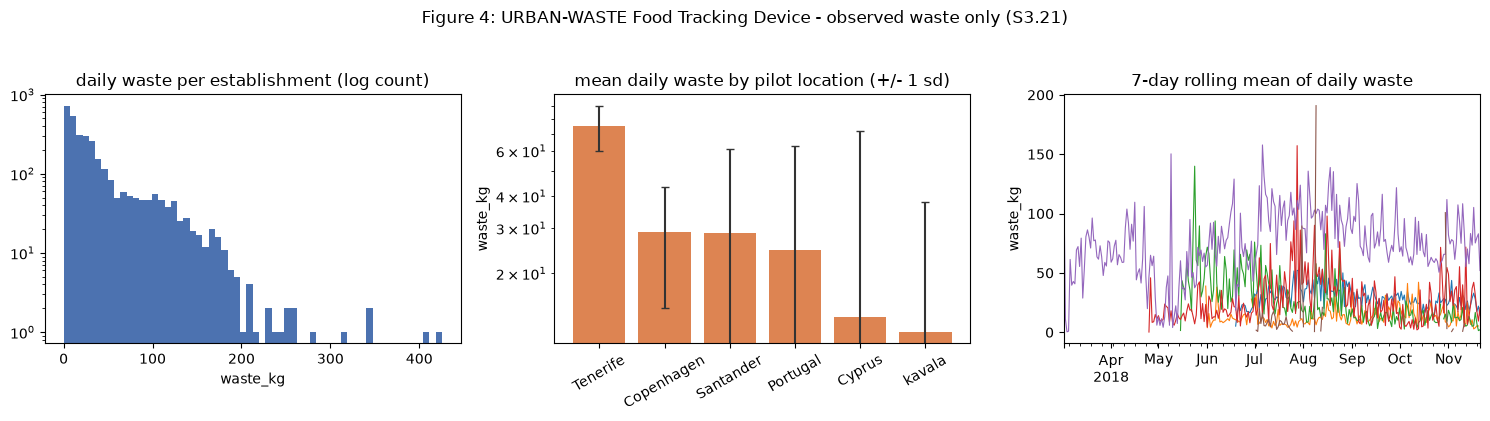

saved /Users/mac/Desktop/DemandIQ/DemandIQ/model/figures/nb01/fig_waste.png


In [8]:
# ==============================================================================
# FIGURE 4 - what the waste data looks like, and why it cannot be forecast.
#
# Log axes on the left and middle panels because the data is right-skewed; the
# middle panel shows why "mean waste by city" alone is misleading, and the right
# panel shows there is no shared weekly rhythm to generalise from.
# ==============================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.hist(ftd["waste_kg"].dropna(), bins=60, color="#4C72B0")
ax.set_yscale("log")
ax.set_title("daily waste per establishment (log count)")
ax.set_xlabel("waste_kg")

loc = (
    ftd.groupby("pilot_location")["waste_kg"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)
ax = axes[1]
ax.bar(loc.index, loc["mean"], color="#DD8452")
ax.errorbar(
    loc.index,
    loc["mean"],
    yerr=ftd.groupby("pilot_location")["waste_kg"].std(),
    fmt="none",
    ecolor="#333333",
    capsize=3,
)
ax.set_yscale("log")
ax.set_title("mean daily waste by pilot location (+/- 1 sd)")
ax.set_ylabel("waste_kg")
ax.tick_params(axis="x", rotation=30)

ax = axes[2]
daily = (
    ftd.dropna(subset=["waste_kg"])
    .groupby(["pilot_location", "date"])["waste_kg"]
    .mean()
    .unstack(0)
    .sort_index()
)
daily.plot(ax=ax, linewidth=0.8, legend=False)
ax.set_title("7-day rolling mean of daily waste")
ax.set_ylabel("waste_kg")
ax.set_xlabel("")

fig.suptitle(
    "Figure 4: URBAN-WASTE Food Tracking Device - observed waste only (S3.21)",
    y=1.04,
)
fig.tight_layout()
out = FIG_DIR / "fig_waste.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
plt.show()
print("saved", out)

## 6. Recruit: the training target and the structure it must model

Rendered from the checkpoints of the run above, so the report's data and model
sections come from the same run as the metrics.

fs-2026.09.2: 251,279 rows x 30 cols | 829 stores | 2016-01-02 -> 2017-04-22


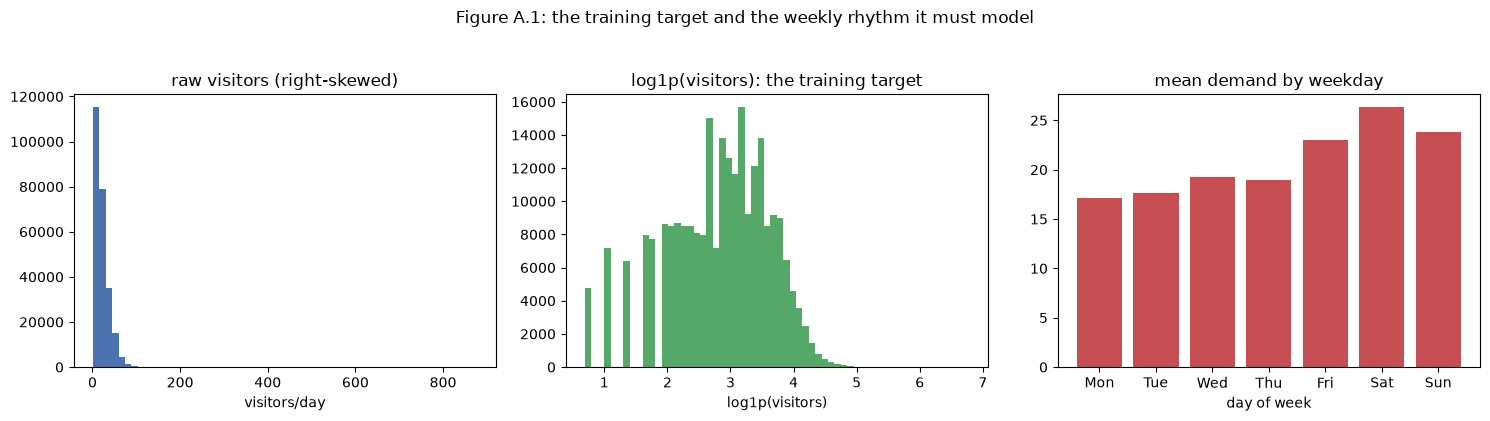

saved /Users/mac/Desktop/DemandIQ/DemandIQ/model/figures/nb01/fig_target.png


In [9]:
# ==============================================================================
# FIGURE A.1 - the target, straight from the checkpoint rather than a copied number.
#
# Left and middle are the reason for log1p: the count distribution is a long right
# tail, its log is symmetric. Right is the weekly rhythm the model must learn.
# Day 0 = Monday (pandas dt.dayofweek).
# ==============================================================================
import importlib.util
import joblib

import os

# If a stale MPLBACKEND points at a backend that cannot be resolved, drop it so
# matplotlib picks a usable one instead of dying with
# "Key backend: '...' is not a valid value for backend".
_backend = os.environ.get("MPLBACKEND", "")
if _backend.startswith("module://") and importlib.util.find_spec(
    _backend[len("module://") :].split(".")[0]
) is None:
    del os.environ["MPLBACKEND"]
    print(f"dropped unusable MPLBACKEND={_backend!r}")

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

features = store.load_dataframe("features.parquet")
meta = store.load_object("features_meta.joblib")
FEATS, TARGET = meta["feature_columns"], meta["target_column"]

print(
    f"{meta['feature_set_version']}: {len(features):,} rows x {features.shape[1]} cols | "
    f"{features['air_store_id'].nunique():,} stores | "
    f"{features['visit_date'].min().date()} -> {features['visit_date'].max().date()}"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(features[TARGET], bins=60, color="#4C72B0")
axes[0].set_title("raw visitors (right-skewed)")
axes[0].set_xlabel("visitors/day")

axes[1].hist(np.log1p(features[TARGET]), bins=60, color="#55A868")
axes[1].set_title("log1p(visitors): the training target")
axes[1].set_xlabel("log1p(visitors)")

by_dow = features.groupby("dow")[TARGET].mean()
axes[2].bar(by_dow.index, by_dow.values, color="#C44E52")
axes[2].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[2].set_title("mean demand by weekday")
axes[2].set_xlabel("day of week")

fig.suptitle("Figure A.1: the training target and the weekly rhythm it must model", y=1.04)
fig.tight_layout()
out = FIG_DIR / "fig_target.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
plt.show()
print("saved", out)

training window: 193,413 rows | 829 stores

target                 skew   excess kurtosis
raw visitors           2.69             39.92
log1p(visitors)       -0.45             -0.17
log(visitors)         -0.71               nan

eta^2 of weekday alone = 0.0359  (3.6% of demand variance)
Kruskal-Wallis H = 6,612   p = 0.00e+00   n = 193,413
weekday mean spread  = 42.3% of the grand mean (20.9 visitors)

on 57,691 held-out rows where dow_mean_8w exists:
  pooled weekday mean   MAE = 12.40
  each store's own mean MAE = 7.13   <- dow_mean_8w



mean |SHAP| on the held-out window (top 6 of 26 features):
  1. dow_mean_8w         45.9%  <-- dow, learned per store
  2. roll_mean_7         12.6%
  3. rsv_visitors         7.2%
  4. roll_mean_28         6.4%
  5. dow                  5.7%  <-- calendar dow
  6. dow_std_8w           4.2%
  -> dow_mean_8w takes 46% of all attribution; raw dow ranks 5.

re-transform bias on held-out: mean(pred)/mean(actual) = 0.922 (-7.8%)


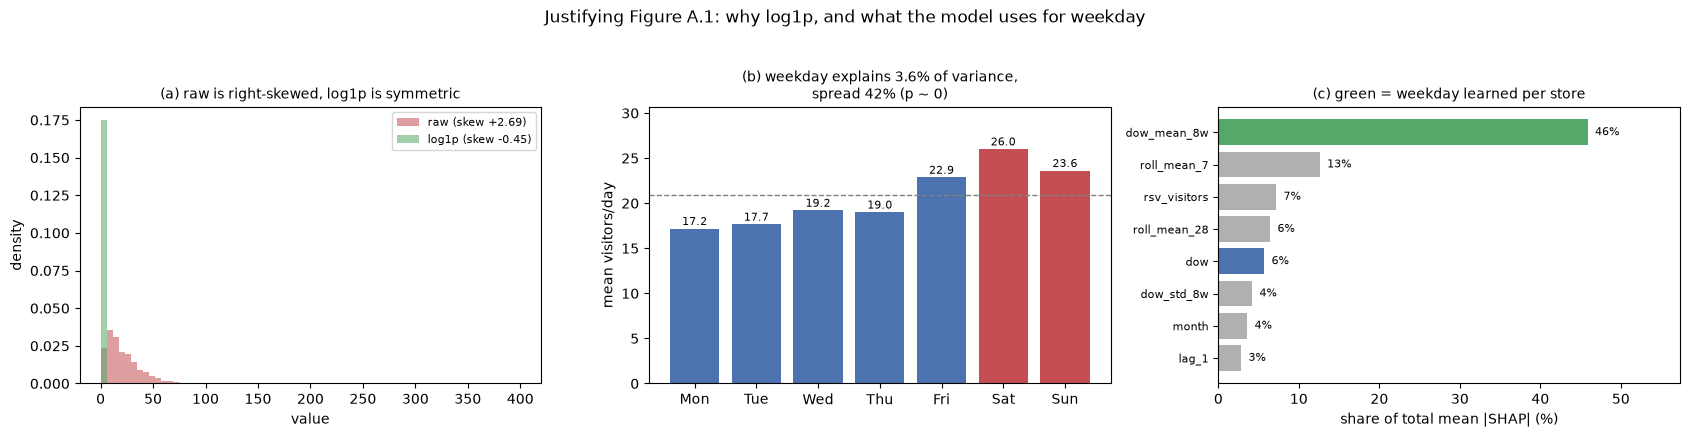


saved /Users/mac/Desktop/DemandIQ/DemandIQ/model/figures/nb01/fig_target_justification.png


In [10]:
# WHY FIGURE A.1 LOOKS THIS WAY - the two claims in it, measured.
#
# log1p: raw visitors are right-skewed (skew 2.7, kurtosis 40), so squared
# error would be dominated by a few extreme days; log1p cuts skew to -0.5.
# log1p not log, because some days record zero visitors and log(0) is undefined.
# The cost: expm1 returns a geometric mean, so we predict ~8% low. Reported below.
#
# Weekday: the strongest recurring pattern, but raw `dow` only ranks 5th. What
# dominates is dow_mean_8w (each store's own weekday mean over 8 weeks) at 46% of
# all attribution, because per-store MAE 7.13 beats pooled 12.40. Weekday alone
# explains 3.6% of variance; the mean spread is 42% of the grand mean.
#
# Stats below use the training window only; attribution uses held-out.
from scipy import stats as _st  # noqa: E402

_train = features[features["visit_date"] < pd.Timestamp(TEST_START)]
_y = _train[TARGET].to_numpy(dtype=float)


def _moments(x):
    return float(_st.skew(x, bias=False)), float(_st.kurtosis(x, bias=False))


_sk_raw, _k_raw = _moments(_y)
_sk_l1p, _k_l1p = _moments(np.log1p(_y))
_sk_log, _ = _moments(np.log(_y))

print(f"training window: {len(_y):,} rows | {features['air_store_id'].nunique():,} stores")
print()
print(f"{'target':<18}{'skew':>9}{'excess kurtosis':>18}")
for _lbl, _s, _k in (
    ("raw visitors", _sk_raw, _k_raw),
    ("log1p(visitors)", _sk_l1p, _k_l1p),
    ("log(visitors)", _sk_log, float("nan")),
):
    print(f"{_lbl:<18}{_s:>9.2f}{_k:>18.2f}")

# --- how much demand does the weekday grouping explain? ---
_g = _train.groupby("dow")[TARGET].agg(["mean", "count"])
_grand = _train[TARGET].mean()
_ssb = (_g["count"] * (_g["mean"] - _grand) ** 2).sum()
_sst = ((_train[TARGET] - _grand) ** 2).sum()
_eta2 = _ssb / _sst
_kw = _st.kruskal(*[_train[TARGET][_train["dow"] == _d].to_numpy() for _d in sorted(_g.index)])

print()
print(f"eta^2 of weekday alone = {_eta2:.4f}  ({100 * _eta2:.1f}% of demand variance)")
print(f"Kruskal-Wallis H = {_kw.statistic:,.0f}   p = {_kw.pvalue:.2e}   n = {len(_train):,}")
_spread = (_g["mean"].max() - _g["mean"].min()) / _grand
print(f"weekday mean spread  = {_spread:.1%} of the grand mean ({_grand:.1f} visitors)")

# --- pooled weekday pattern vs each store's own weekday pattern ---
_test = features[features["visit_date"] >= pd.Timestamp(TEST_START)]
_pooled = _train.groupby("dow")[TARGET].mean()
_ok = _test["dow_mean_8w"].notna()
_sub = _test[_ok]
_pooled_pred = _sub["dow"].map(_pooled)
_store_pred = _sub["dow_mean_8w"]
mae_pooled = float(np.mean(np.abs(_sub[TARGET] - _pooled_pred)))
mae_store = float(np.mean(np.abs(_sub[TARGET] - _store_pred)))
print()
print(f"on {_ok.sum():,} held-out rows where dow_mean_8w exists:")
print(f"  pooled weekday mean   MAE = {mae_pooled:.2f}")
print(f"  each store's own mean MAE = {mae_store:.2f}   <- dow_mean_8w")

# --- where the model's attribution actually goes ---
if store.has("shap_contributions.parquet"):
    _sh = store.load_dataframe("shap_contributions.parquet")
    _sh = _sh[_sh["visit_date"] >= pd.Timestamp(TEST_START)]
    _att = _sh.assign(_a=_sh["shap_impact"].abs()).groupby("feature_name")["_a"].mean().sort_values(ascending=False)
    _share = _att / _att.sum()
    print()
    print(f"mean |SHAP| on the held-out window (top 6 of {len(_att)} features):")
    for _i, (_f, _v) in enumerate(_share.head(6).items(), start=1):
        _mark = "  <-- calendar dow" if _f == "dow" else ("  <-- dow, learned per store" if _f == "dow_mean_8w" else "")
        print(f"  {_i}. {_f:<18}{_v:>7.1%}{_mark}")
    _rank = list(_att.index).index("dow") + 1
    print(f"  -> dow_mean_8w takes {_share['dow_mean_8w']:.0%} of all attribution; raw dow ranks {_rank}.")
else:
    _att = _share = _rank = None

# --- the cost of the log1p round trip ---
_preds = store.load_dataframe("lightgbm_predictions.parquet")
_mean_pred = float(_preds["prediction"].mean())
_mean_act = float(_test[TARGET].mean())
print()
print(f"re-transform bias on held-out: mean(pred)/mean(actual) = {_mean_pred / _mean_act:.3f} "
      f"({_mean_pred / _mean_act - 1:+.1%})")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

# (a) skew before vs after, on a common count scale
axes[0].hist(_y, bins=70, range=(0, 400), density=True, alpha=0.55, color="#C44E52", label=f"raw (skew {_sk_raw:+.2f})")
axes[0].hist(np.log1p(_y), bins=70, range=(0, 400), density=True, alpha=0.55, color="#55A868", label=f"log1p (skew {_sk_l1p:+.2f})")
axes[0].set_xlabel("value")
axes[0].set_ylabel("density")
axes[0].set_title("(a) raw is right-skewed, log1p is symmetric", fontsize=10)
axes[0].legend(fontsize=8)

# (b) the weekday pattern, with its practical effect size
_means = _g["mean"]
axes[1].bar(range(7), _means.values, color=["#4C72B0" if i < 5 else "#C44E52" for i in range(7)])
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].axhline(_grand, ls="--", lw=1, color="grey")
axes[1].set_ylim(0, _means.max() * 1.18)
axes[1].set_ylabel("mean visitors/day")
axes[1].set_title(f"(b) weekday explains {100 * _eta2:.1f}% of variance,\nspread {_spread:.0%} (p ~ 0)", fontsize=10)
for _i, _v in enumerate(_means.values):
    axes[1].text(_i, _v + 0.4, f"{_v:.1f}", ha="center", fontsize=8)

# (c) attribution: what the model actually uses
if _share is not None:
    _top = _share.head(8)[::-1] * 100  # plot in percent so labels sit inside the axes
    _cols = ["#55A868" if _f == "dow_mean_8w" else ("#4C72B0" if _f == "dow" else "#B0B0B0") for _f in _top.index]
    axes[2].barh(range(len(_top)), _top.values, color=_cols)
    axes[2].set_yticks(range(len(_top)), _top.index, fontsize=8)
    axes[2].set_xlim(0, float(_top.max()) * 1.25)
    axes[2].set_xlabel("share of total mean |SHAP| (%)")
    axes[2].set_title("(c) green = weekday learned per store", fontsize=10)
    for _i, _v in enumerate(_top.values):
        axes[2].text(_v + _top.max() * 0.02, _i, f"{_v:.0f}%", va="center", fontsize=8)

fig.suptitle("Justifying Figure A.1: why log1p, and what the model uses for weekday", y=1.03)
fig.tight_layout()
out = FIG_DIR / "fig_target_justification.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
plt.show()
print("\nsaved", out)

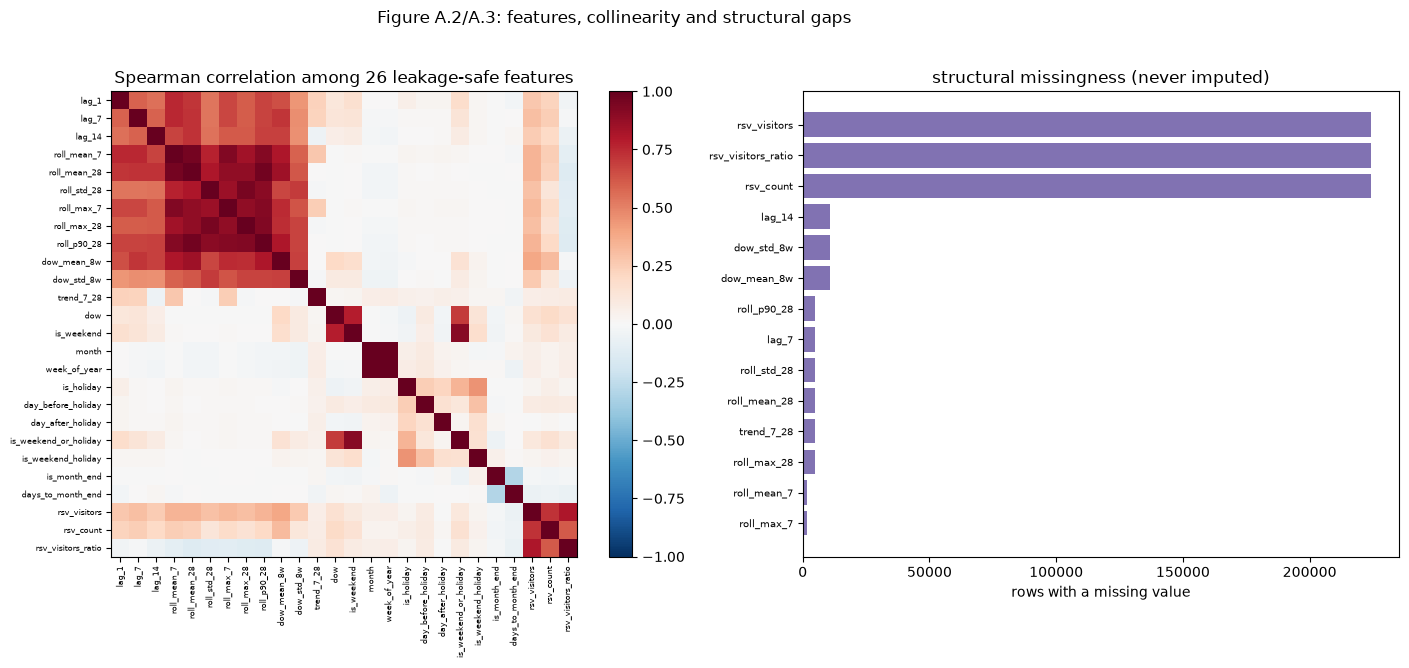

saved /Users/mac/Desktop/DemandIQ/DemandIQ/model/figures/nb01/fig_corr_missing.png | features carrying nulls: 14 of 26


In [11]:
# ==============================================================================
# FIGURES A.2 / A.3 - collinearity, and why nothing is imputed.
#
# Spearman, not Pearson: heavy tails and structural gaps distort linear
# correlation. The missing values are structural (a young store has no history, only
# a third of stores have a reservation feed), so imputing would teach a falsehood.
# LightGBM routes nulls down its own learned branch instead.
# ==============================================================================
corr = features[FEATS].corr(method="spearman")
nulls = features[FEATS].isna().sum().sort_values(ascending=False)
present = nulls[nulls > 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.15, 0.85]})
im = axes[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(FEATS)), FEATS, rotation=90, fontsize=6)
axes[0].set_yticks(range(len(FEATS)), FEATS, fontsize=6)
axes[0].set_title(f"Spearman correlation among {len(FEATS)} leakage-safe features")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].barh(present.index[::-1], present.values[::-1], color="#8172B2")
axes[1].set_xlabel("rows with a missing value")
axes[1].set_title("structural missingness (never imputed)")
axes[1].tick_params(axis="y", labelsize=7)

fig.suptitle("Figure A.2/A.3: features, collinearity and structural gaps", y=1.02)
fig.tight_layout()
out = FIG_DIR / "fig_corr_missing.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
plt.show()
print(f"saved {out} | features carrying nulls: {len(present)} of {len(FEATS)}")

LightGBM architecture (primary)
           objective: regression
              metric: rmse
       learning_rate: 0.05
          num_leaves: 63
    min_data_in_leaf: 40
    feature_fraction: 0.9
    bagging_fraction: 0.9
           lambda_l2: 1.0
       deterministic: True
          trees kept: 200 of 2000 (early stopped, patience 100)
    target transform: log1p(visitors) -> expm1, clipped at 0


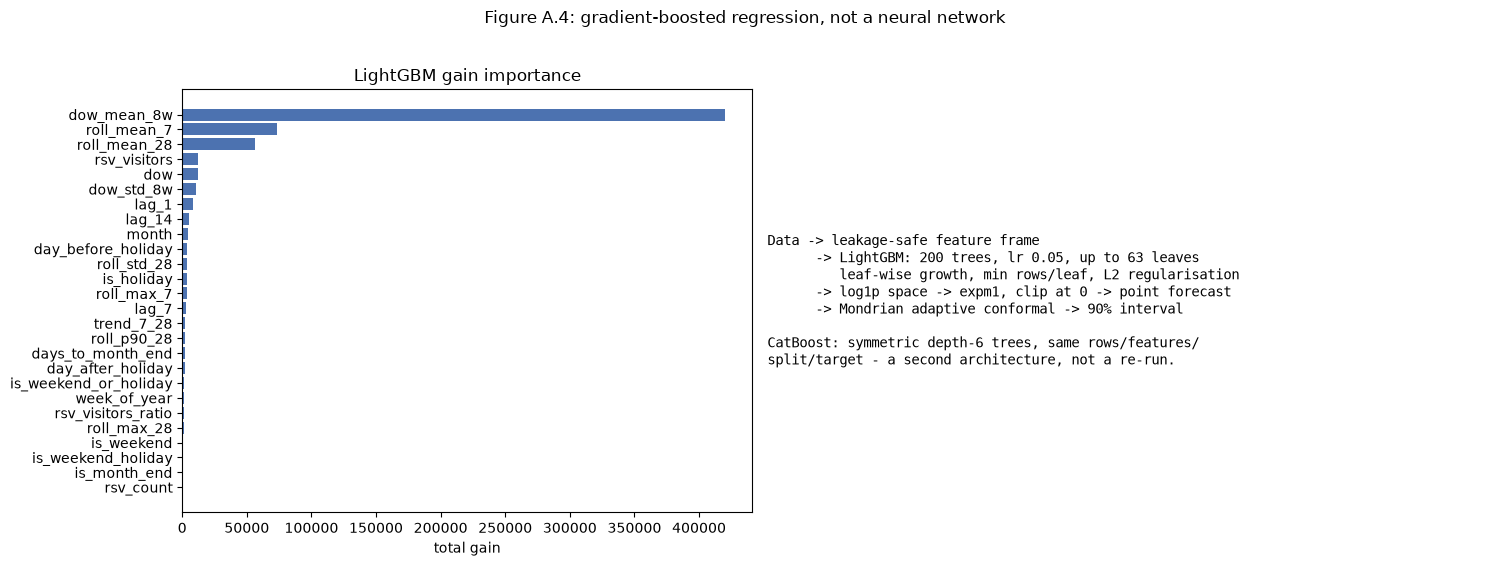

saved /Users/mac/Desktop/DemandIQ/DemandIQ/model/figures/nb01/fig_architecture.png


In [12]:
# ==============================================================================
# FIGURE A.4 - the fitted model, read off the model object, not a config file.
#
# Parameters are printed from the booster so they match the metrics above; trees
# kept is the early-stopping result, taken on the last 10% of the training window
# and never on the held-out window. Gain importance weights features by loss
# reduced, so it is comparable across cardinalities.
# ==============================================================================
# Architecture + feature importance for the trained booster.
SHAP_TOP_N = 12  # how many drivers to plot, straight from the trained booster.
if not store.has("lightgbm_model.joblib"):
    print("no lightgbm_model.joblib in this run - rerun the pipeline cell.")
else:
    model = store.load_object("lightgbm_model.joblib")
    params = model.params
    print("LightGBM architecture (primary)")
    for k in (
        "objective",
        "metric",
        "learning_rate",
        "num_leaves",
        "min_data_in_leaf",
        "feature_fraction",
        "bagging_fraction",
        "lambda_l2",
        "deterministic",
    ):
        print(f"  {k:>18}: {params.get(k)}")
    print(
        f"  {'trees kept':>18}: {model.best_iteration_} of {model.num_boost_round} "
        f"(early stopped, patience 100)"
    )
    print(f"  {'target transform':>18}: log1p(visitors) -> expm1, clipped at 0")

    imp = pd.Series(
        model.booster_.feature_importance(importance_type="gain"),
        index=model.feature_columns_,
    ).sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
    axes[0].barh(imp.index, imp.values, color="#4C72B0")
    axes[0].set_title("LightGBM gain importance")
    axes[0].set_xlabel("total gain")

    axes[1].axis("off")
    axes[1].text(
        0,
        0.5,
        "Data -> leakage-safe feature frame\n"
        f"      -> LightGBM: {model.best_iteration_} trees, lr {params.get('learning_rate')}, "
        f"up to {params.get('num_leaves')} leaves\n"
        "         leaf-wise growth, min rows/leaf, L2 regularisation\n"
        "      -> log1p space -> expm1, clip at 0 -> point forecast\n"
        "      -> Mondrian adaptive conformal -> 90% interval\n\n"
        "CatBoost: symmetric depth-6 trees, same rows/features/\n"
        "split/target - a second architecture, not a re-run.",
        family="monospace",
        va="center",
        fontsize=10,
    )
    fig.suptitle("Figure A.4: gradient-boosted regression, not a neural network", y=1.02)
    fig.tight_layout()
    out = FIG_DIR / "fig_architecture.png"
    fig.savefig(out, dpi=130, bbox_inches="tight")
    plt.show()
    print("saved", out)

**Reading.** The target is right-skewed, which is why the model trains on
`log1p(visitors)` and is scored with RMSLE; the weekday bars are the second
structure it exploits. The correlation map shows the historical-demand block is
near-collinear (hence 90% feature subsampling per tree), and missingness is
structural - new stores lack history and only about a third of stores have a
reservation feed - so nothing is imputed; boosted trees route a NaN down its own
branch. The architecture is a gradient-boosted tree ensemble: the "layers" are
boosting rounds, the activation analogue is the learning rate, and optimisation
is least-squares on log1p targets. CatBoost is a genuine second architecture,
which is why S3.13 keeps both. URBAN-WASTE characterises waste only - with 9
rows carrying both waste and ordered portions it cannot serve as a label, which
is exactly why S3.21 treats it as a boundary rather than a target.

## 7. Package the artifact bundle

In [13]:
# ==============================================================================
# BUNDLE - zip the run directory to hand it over as one file. The directory is
# already the artifact; this adds nothing analytically. Run only after the pipeline.
# ==============================================================================
# The run directory is already the artifact (parquet checkpoints + manifest.json).
# This zip is only for off-machine inspection / registration.
import zipfile

bundle = CKPT_DIR.parent / f"demandiq-nb01-{SEED}.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(CKPT_DIR.rglob("*")):
        if f.is_file():
            zf.write(f, f.relative_to(CKPT_DIR.parent))
print(f"Bundle: {bundle} ({bundle.stat().st_size / 1e6:.1f} MB)")
print(f"Figures: {FIG_DIR}")

Bundle: /Users/mac/Desktop/DemandIQ/DemandIQ/model/artifacts/runs/demandiq-nb01-42.zip (26.5 MB)
Figures: /Users/mac/Desktop/DemandIQ/DemandIQ/model/figures/nb01
